# Chapter 3 — Dimensionality Reduction Techniques

**Nama:** Omar Al Farizy Hutagalung

**NIM:** 101032300034  

**Mata Kuliah:** Machine Learning  

**Tugas:** Tugas 2 — Code Reproduction & Theoretical Deep-Dive

---

## Objective

Chapter ini membahas dimensionality reduction untuk mengurangi jumlah fitur
dengan tetap mempertahankan informasi penting dalam dataset.

Teknik yang dibahas meliputi feature selection, PCA, LDA, dan t-SNE.

## 1. Dimensionality Reduction

Dimensionality reduction digunakan untuk mengurangi jumlah dimensi atau fitur
pada dataset.

Tujuan utamanya antara lain:
- Mengurangi kompleksitas model.
- Mempercepat proses training.
- Mengurangi risiko overfitting.
- Membantu visualisasi data berdimensi tinggi.

Ada dua pendekatan utama:

**Feature Selection**
Memilih sebagian fitur asli tanpa mengubah representasinya.

**Feature Extraction**
Mengubah fitur asli menjadi representasi baru dengan jumlah dimensi lebih
sedikit.

PCA, LDA, dan t-SNE termasuk teknik feature extraction.

## 2. Principal Component Analysis (PCA)

PCA mengubah fitur asli menjadi sejumlah principal components.

Principal components dipilih berdasarkan arah dengan variasi data terbesar.
Dengan memilih beberapa komponen pertama, jumlah dimensi dapat dikurangi
sambil mempertahankan sebagian besar informasi.

PCA merupakan metode unsupervised karena tidak menggunakan target class
ketika menentukan komponen.

In [1]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

wine = load_wine()

X = wine.data
y = wine.target

# Standardisasi
X_scaled = StandardScaler().fit_transform(X)

# PCA menjadi 2 komponen
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X.shape)
print("Reduced shape:", X_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

Original shape: (178, 13)
Reduced shape: (178, 2)
Explained variance: [0.36198848 0.1920749 ]
Total explained variance: 0.5540633835693526


### Analysis

Dataset Wine memiliki 13 fitur. Setelah PCA, data direduksi menjadi 2
komponen utama.

`explained_variance_ratio_` menunjukkan proporsi variasi data yang dijelaskan
oleh setiap principal component.

## 3. PCA vs LDA

PCA dan LDA sama-sama dapat digunakan untuk dimensionality reduction, tetapi
memiliki tujuan yang berbeda.

| PCA | LDA |
|---|---|
| Unsupervised | Supervised |
| Tidak menggunakan target | Menggunakan target/class |
| Memaksimalkan variance | Memaksimalkan class separability |
| Fokus pada struktur data | Fokus pada pemisahan kelas |

PCA cocok ketika struktur variasi data ingin dipertahankan, sedangkan LDA
lebih sesuai ketika informasi class tersedia dan pemisahan antar-class menjadi
tujuan utama.

In [2]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_scaled, y)

print("Original shape:", X.shape)
print("LDA shape:", X_lda.shape)

Original shape: (178, 13)
LDA shape: (178, 2)


### Analysis

Berbeda dengan PCA, LDA menggunakan label `y` ketika menentukan representasi
berdimensi rendah.

Pada dataset Wine yang memiliki tiga kelas, LDA dapat menghasilkan maksimal
dua komponen karena jumlah komponen dibatasi oleh jumlah kelas dikurangi satu.

## 4. t-SNE

t-SNE merupakan teknik dimensionality reduction yang terutama berguna untuk
visualisasi data berdimensi tinggi.

Berbeda dengan PCA yang berusaha mempertahankan variance secara global,
t-SNE berfokus pada struktur lokal dan kedekatan antar data.

Karena itu, t-SNE sering digunakan untuk menghasilkan representasi 2D atau
3D untuk visualisasi.

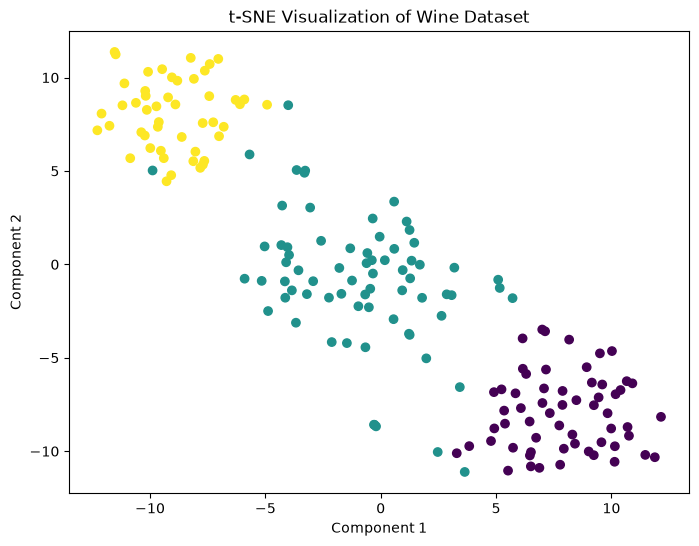

In [3]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y
)
plt.title("t-SNE Visualization of Wine Dataset")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

### Analysis

t-SNE menghasilkan representasi dua dimensi yang dapat digunakan untuk
melihat pola pengelompokan data secara visual.

Hasil visualisasi tidak digunakan sebagai pengganti evaluasi model, tetapi
berguna untuk memahami struktur lokal dataset.

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Tanpa PCA
model_original = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=200))
])

# Dengan PCA
model_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2)),
    ("model", LogisticRegression(max_iter=200))
])

model_original.fit(X_train, y_train)
model_pca.fit(X_train, y_train)

pred_original = model_original.predict(X_test)
pred_pca = model_pca.predict(X_test)

print("Accuracy without PCA:", accuracy_score(y_test, pred_original))
print("Accuracy with PCA:", accuracy_score(y_test, pred_pca))

Accuracy without PCA: 0.9333333333333333
Accuracy with PCA: 0.9


## Conclusion

Dimensionality reduction dapat mengurangi jumlah fitur, mempercepat proses
modeling, dan membantu visualisasi data.

PCA mempertahankan variasi data terbesar tanpa menggunakan label, sedangkan
LDA menggunakan label untuk meningkatkan pemisahan antar-class. t-SNE lebih
berfokus pada visualisasi dan struktur lokal.

Pemilihan teknik harus mempertimbangkan tujuan, karakteristik dataset,
kebutuhan komputasi, serta dampaknya terhadap performa model.